## EXD-Net v1: Binary Hopfield Networks

- Binary hopfields can exactly reconstruct stored patterns from a noisy input
- The goal of this project was to see how interference would affect the matrix
- Toy experiment on recall (given a cue) as new associations are added to a Hopfield network
- 7 scenes with corresponding old pattern (ex), new pattern (benji), and background context (bg)
- Network initially trained on old associations (W_initial)
- New incoming information adds the new patterns while preserving the initial weight contribution

### Questions
- Does the recall reach a fixed point?
- How similar do the outputs resemble the patterns? 
- How do the old/new patterns energies change over time? 





In [1]:
from pathlib import Path 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
from PIL import Image

sns.set_theme()

In [2]:
IMG_DIR = Path("images")
SCENES = ["beach","christmas","movie","night","surf","brunch","picnic"]
    

# these are all arbitrary 
SEED = 12
IMG_SIZE = 32
BASELINE_PASS = 10 # initial weight matrix of old pattern strength (ex) 
N_GLOBAL_UPDATES = 30 # random scene selection to add new pattern / test retrieval 
NOISE_LEVEL = 0.10 # noise level cue
MAX_STEPS = 10 # max update for each retrieval 

RNG = np.random.default_rng(SEED)


In [3]:
def preprocess_img(path,size=IMG_SIZE): 
    with Image.open(path) as img: 
        grayscale = img.convert("L").resize((size,size))
    pixels = np.asarray(grayscale)
    return np.where(pixels > 127,1,-1).ravel() # 225/2 discrete pixel states of threshold +1 (active) -1 (inactive) 


In [4]:
def load_imgs(path,scenes=SCENES,size=IMG_SIZE): 
    memory_dict = {}

    for scene in scenes: 
        for suffix in ["bg","ex","benji"]: 
            scene_name = f"{scene}_{suffix}"
            file_name = scene_name + ".png"
            memory_dict[scene_name] = preprocess_img(path / file_name,size) 
    return memory_dict 


In [5]:
memory_dict = load_imgs(IMG_DIR)
print(f"{len(memory_dict)} patterns") # 7 scenes * 3 patterns (context, old, new)

21 patterns


In [6]:
def plot_state(pattern,title,ax=None,size=IMG_SIZE): 
    if ax is None: 
        fig, ax = plt.subplots() 

    ax.imshow(pattern.reshape(size,size),cmap="gray",vmin=-1,vmax=1,interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
    return ax


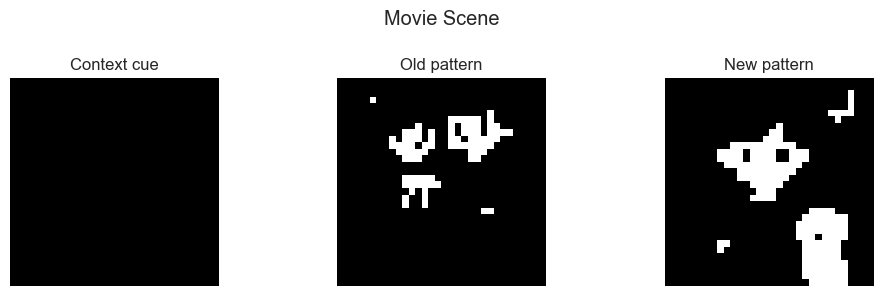

In [7]:
fig,ax = plt.subplots(1,3,figsize=(10,3))
for axis, suffix, label in zip(ax,("bg","ex","benji"), ("Context cue", "Old pattern","New pattern")): 
    plot_state(memory_dict[f"movie_{suffix}"],label,axis)

fig.suptitle("Movie Scene")
plt.tight_layout()
plt.show()

## Pattern similarity pre-training
- Binary ($\pm1$) vectors  of equal lengths, hamming distance & cosine similarity are not independent metrics: 

    -  $1-\frac{2d_H(x,y)}{N} = cos(x,y)$

- Used both for interpretation and to check consistency

In [8]:
def hamming_dist(pattern1,pattern2):
    return int(np.sum(pattern1 != pattern2))

In [9]:
def bipolar_cosine(pattern1,pattern2): 
    return np.dot(pattern1,pattern2)/len(pattern1)


In [10]:
data = []
pairs = [("bg","ex"),("bg","benji"), ("ex","benji")]
for scene in SCENES: 
    for a,b in pairs: 
        ham = hamming_dist(memory_dict[f"{scene}_{a}"], memory_dict[f"{scene}_{b}"])
        cos = bipolar_cosine(memory_dict[f"{scene}_{a}"],memory_dict[f"{scene}_{b}"])
        data.append({"scene":scene,"pair":f"{a} vs {b}", "hamming":ham,"cosine":cos})


paired_df = pd.DataFrame(data)
paired_df.head()

# identical patterns: hamming = 0, cos = 1
# more mismatches: larger hamming, smaller cos 

,scene,pair,hamming,cosine
0,beach,bg vs ex,413,0.193359
1,beach,bg vs benji,506,0.011719
2,beach,ex vs benji,513,-0.001953
3,christmas,bg vs ex,272,0.468750
4,christmas,bg vs benji,398,0.222656


,scene,pair,hamming,cosine
6,movie,bg vs ex,84,0.835938
7,movie,bg vs benji,169,0.669922
8,movie,ex vs benji,193,0.623047


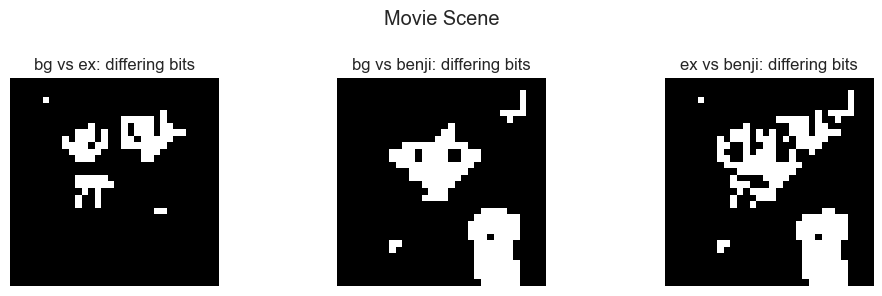

In [11]:
movie_subset = paired_df[paired_df["scene"] == "movie"]
display(movie_subset)

fig,axs = plt.subplots(1,3,figsize=(10,3))
for ax, (a,b) in zip(axs, pairs): 
    pix_diff = memory_dict[f"movie_{a}"] != memory_dict[f"movie_{b}"]
    plot_state(2*pix_diff.astype(int)-1,f"{a} vs {b}: differing bits",ax) # change the binary back to -1,1 
plt.suptitle("Movie Scene")
plt.tight_layout()



- Hamming distance tells us the number of differing pixels from each
    
    - Context vs old = 84 pixels
    - Context vs new = 169 pixels 
    - Old vs new = 193 pixels 

- Here context is closer to the old pattern (cosine similarity also indicates that as well 0.8) 

## Hopfield model


In [12]:
def train_hopfield(patterns,repeats=BASELINE_PASS): 
    n = len(patterns[0])
    W = np.zeros((n,n))

    for pattern in patterns: 
        W += np.outer(pattern,pattern) * repeats # (10 repeats)
    W /= len(patterns) # keep original scale (7 patterns)
    np.fill_diagonal(W,0) # prevents self connections
    return W 



In [13]:
def reinforce_memory(W,new_pattern): 
    W += np.outer(new_pattern,new_pattern)
    np.fill_diagonal(W,0)
    return W

- Initial matrix is the sum of the outer products of the 7 old patterns multiplied by an arbitrary base of 10, divided by the 7 patterns, and then removes the self-connections. 
- New exposure adds an outer product of the new pattern and sets the diagonal to 0. 

$$W_t = \frac{10}{7} \sum_{s=1}^7 o_so_s^T + \sum_{k=1}^t n_{sk}n_{sk}^T$$

- *where o = old, n = new*

- 



In [14]:
def energy(W,state): 
    return -0.5 * state @ W @ state 

In [15]:
def recall_async(W,cue_pattern,steps=MAX_STEPS):
    state = cue_pattern.copy()
    energy_trace = [energy(W,state)]
    for step in range(steps): 
        changed = False
        indices = RNG.permutation(len(state)) # randomized to avoid update order bias 
        for idx in indices: 
            net_input = np.dot(W[idx],state) # each neuron is randomly updated based on current global state 
            if net_input >= 0: 
                new_val = 1
            else: 
                new_val = -1 
            if state[idx] != new_val: # did the neuron change 
                state[idx] = new_val
                changed = True
        energy_trace.append(energy(W,state))
        if not changed: 
            return state, step + 1, "fixed_point", energy_trace # if a step has no flips then there is a fixed point given max steps (by that i mean it settled into a unchanged state by this many steps)
    return state, steps, "max_steps", energy_trace 



In [16]:
def recall_sync(W,cue_pattern,steps=MAX_STEPS): # not used 
    state = cue_pattern.copy()
    previous_state = None
    energy_trace = [energy(W,state)]
    for step in range(steps): 
        new_state = np.sign(W@state) # all neurons update from previous state (this can cause cycling)
        new_state[new_state==0] = 1 
        energy_trace.append(energy(W,new_state))
        if np.array_equal(new_state,state): 
            return new_state, step + 1, "fixed_point", energy_trace
        if previous_state is not None and np.array_equal(new_state,previous_state): 
            return new_state, step + 1, "two_cycle", energy_trace 
        previous_state = state.copy()
        state = new_state
    return state, steps, "max_steps", energy_trace 


In [17]:
def add_noise(pattern,noise_level=NOISE_LEVEL):
    p = pattern.copy()
    n = len(p) 
    flip_bits = RNG.choice(n,size=int(n*noise_level),replace=False)
    p[flip_bits] *= -1 
    return p 

In [18]:
def is_fixed_point(W,pattern): 
    for idx in range(len(pattern)):
        net_input = np.dot(W[idx],pattern)
        if net_input >= 0:
            new_val = 1 
        else: 
            new_val = -1 
        if new_val != pattern[idx]:
            return False
    return True 

- `recall_async` is initiated by a (noisy) context cue and then updates one neuron at a time at the current state (sync updates them all at once)
- Weights remain fixed during recall 
- Each step is one sweep through (32*32) 1024 neurons in randomized order (with max step = 10)
- Recall sync meant to be for comparison 

- `energy` is recorded pre/post each step 
$$E(x) = -\frac{1}{2}x^TWx$$

- Fixed point is when a step has no changes
- `is_fixed_point` checks if given pattern would be changed
    - Does not look to see if noisy context reaches the intended pattern 

## Baseline example (trained on old patterns)

In [19]:
old_patterns = [memory_dict[f"{scene}_ex"] for scene in SCENES]

W_initial = train_hopfield(old_patterns) # trained on old pattern 

Base matrix: (1024, 1024) | Steps: 3 | Status: fixed_point


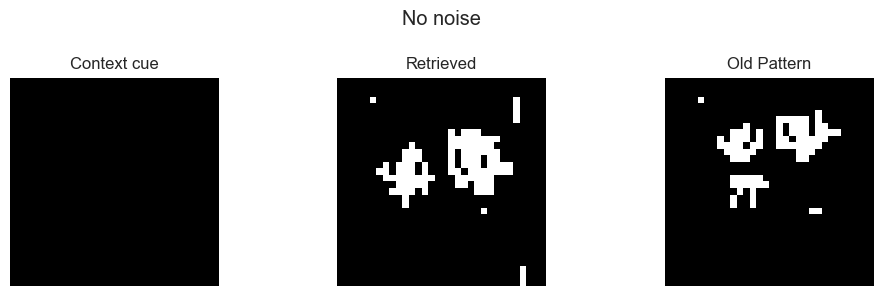

In [20]:
cue_context = memory_dict["movie_bg"]
old_pattern = memory_dict["movie_ex"]

output,steps,status,_ = recall_async(W_initial,cue_context) # no noise 

# print(f"{output} | {steps} | {status} | {baseline_energy_trace}")
print(f"Base matrix: {W_initial.shape} | Steps: {steps} | Status: {status}")

fig, axs = plt.subplots(1,3,figsize=(10,3))
for ax,pattern,title in zip(axs,(cue_context,output,old_pattern), ("Context cue", "Retrieved", "Old Pattern")): 
    plot_state(pattern,title,ax)
plt.suptitle("No noise")
plt.tight_layout()
plt.show()

Base matrix: (1024, 1024) | Steps: 3 | Status: fixed_point


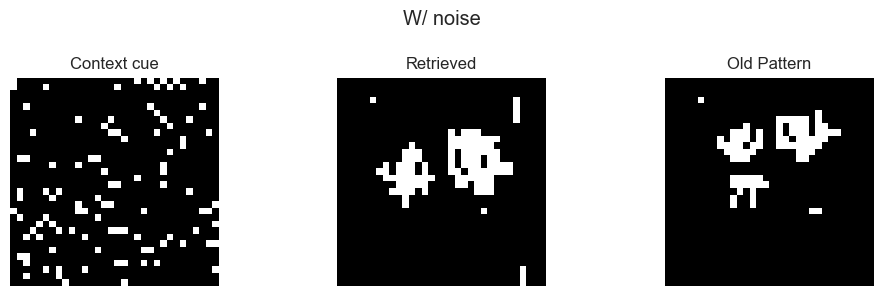

In [21]:
noisy_context = add_noise(cue_context)
noisy_output,steps,status,_ = recall_async(W_initial,noisy_context) # with noise
print(f"Base matrix: {W_initial.shape} | Steps: {steps} | Status: {status}")

fig, axs = plt.subplots(1,3,figsize=(10,3))
for ax,pattern,title in zip(axs,(noisy_context,noisy_output,old_pattern), ("Context cue", "Retrieved", "Old Pattern")): 
    plot_state(pattern,title,ax)
plt.suptitle("W/ noise")
plt.tight_layout()
plt.show()

In [22]:
print(f"Number of noisy pixels: {hamming_dist(cue_context,noisy_context)}") # diff between clean vs noisy cue 
print(f"Diff between no noise vs noise output: {hamming_dist(output,noisy_output)}") # clean/noisy cues had the same output 
print(f"Reconstruction error of noisy output to old pattern: {hamming_dist(noisy_output,old_pattern)} ") # noisy output differed from trained-on output 

Number of noisy pixels: 102
Diff between no noise vs noise output: 0
Reconstruction error of noisy output to old pattern: 104 


- Both clean and noisy movie cues were able to reach the same fixed point in 3 steps.
- Neither output matched the old pattern. 
- Identical outputs suggest robustness in this example despite imperfect reconstruction


## Add competing associations (new pattern)

In [23]:
W = W_initial.copy() # keep original old pattern weight matrix 

data = [] 
energy_traces = []
scene_exposure = {}
turnpoint = {}

for scene in SCENES: 
    scene_exposure[scene] = 0 
    turnpoint[scene] = None 

for global_step in range(1, N_GLOBAL_UPDATES + 1): 
    scene = str(RNG.choice(SCENES))
    scene_exposure[scene] += 1 
    context = memory_dict[f"{scene}_bg"]
    old = memory_dict[f"{scene}_ex"]
    new = memory_dict[f"{scene}_benji"]

    reinforce_memory(W,new) 
    noisy_cue = add_noise(context)
    recalled, steps, status, energy_trace = recall_async(W,noisy_cue,MAX_STEPS)
    energy_traces.append(energy_trace)

    old_sim, new_sim = bipolar_cosine(recalled,old), bipolar_cosine(recalled,new) # compare similarity of retrieved output from old patterns to new patterns 
    delta_sim = new_sim - old_sim 

    if delta_sim > 0: 
        closer = "new" 
    elif delta_sim < 0:
        closer = "old"
    else: 
        closer = "tied"

    if turnpoint[scene] is None and closer == "new": # at what step did it first recall the new pattern (retrieved was closer to new than old)
        turnpoint[scene] = global_step

    data.append({
        "global_step":global_step,
        "scene":scene,
        "scene_exposure": scene_exposure[scene], 
        "exact_old": np.array_equal(recalled,old),
        "exact_new": np.array_equal(recalled, new),
        "closer_pattern": closer,
        "cosine_old": old_sim,
        "cosine_new": new_sim,
        "delta_cosine": delta_sim,
        "hamming_old": hamming_dist(recalled,old), 
        "hamming_new": hamming_dist(recalled, new), 
        "steps": steps, 
        "status":status, 
        "turnpoint":turnpoint[scene],
        "energy_old": energy(W,old), 
        "energy_new": energy(W,new),
        "delta_energy": energy(W,new) - energy(W,old),
        "energy_retrieved": energy(W,recalled),
        "energy_cue": energy(W,noisy_cue)
    })

    last_run = (scene,noisy_cue.copy(),recalled.copy(),old.copy(),new.copy())
    
new_df = pd.DataFrame(data)
W_final = W.copy() # new weights with competing new associations post 30 runs 

print(f"Scene exposure count: {scene_exposure}") 
display(new_df.head().round(3))


Scene exposure count: {'beach': 5, 'christmas': 4, 'movie': 5, 'night': 5, 'surf': 3, 'brunch': 4, 'picnic': 4}


,global_step,scene,scene_exposure,exact_old,exact_new,closer_pattern,cosine_old,cosine_new,delta_cosine,hamming_old,hamming_new,steps,status,turnpoint,energy_old,energy_new,delta_energy,energy_retrieved,energy_cue
0,1,brunch,1,False,False,old,0.557,0.223,-0.334,227,398,3,fixed_point,NaN,-1330610.000,-711453.143,619156.857,-2009145.714,-196294.571
1,2,brunch,2,False,False,new,0.357,0.824,0.467,329,90,4,fixed_point,2.0,-1363380.000,-1235229.143,128150.857,-1242452.000,-225814.286
2,3,christmas,1,False,False,old,0.750,0.242,-0.508,128,388,4,fixed_point,NaN,-1768412.000,-732502.286,1035909.714,-2060922.857,-310376.571
3,4,beach,1,False,False,old,0.799,-0.027,-0.826,103,526,4,fixed_point,NaN,-1867742.857,-751764.000,1115978.857,-2060802.857,-252956.000
4,5,picnic,1,False,False,old,0.779,0.170,-0.609,113,425,4,fixed_point,NaN,-1843565.714,-816638.857,1026926.857,-2075062.000,-89011.714


- Using the initial matrix (W_initial) that was trained on old patterns, add 30 runs via `reinforce_memory` of the new pattern
- Each run randomly chooses one scene and reinforces the new scene pattern 
- A noisy cue is given for that scene and records the output similarity between old/new under that current weight (learning)
- All scenes are saved in one matrix so an update to one scene can affect other scenes despite not all scenes having equal runs.


## Recall example (last trial)

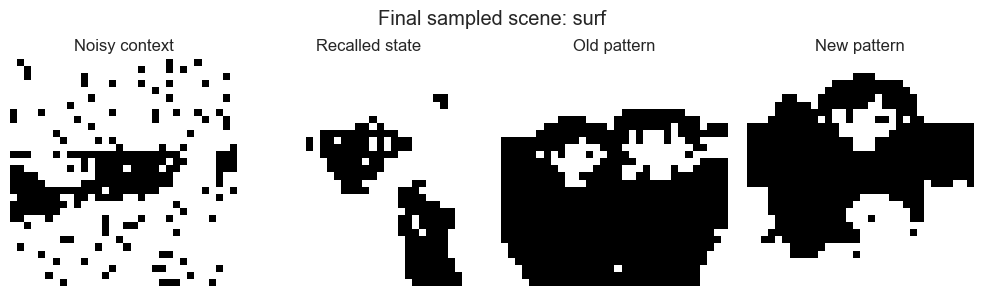

In [24]:
scene, noisy, recalled, old, new = last_run

fig,axs = plt.subplots(1,4,figsize=(10,3))
for ax,pattern,title in zip(axs, (noisy,recalled,old,new),("Noisy context", "Recalled state", "Old pattern", "New pattern")): 
    plot_state(pattern,title,ax)
fig.suptitle(f"Final sampled scene: {scene}")
plt.tight_layout()
plt.show()

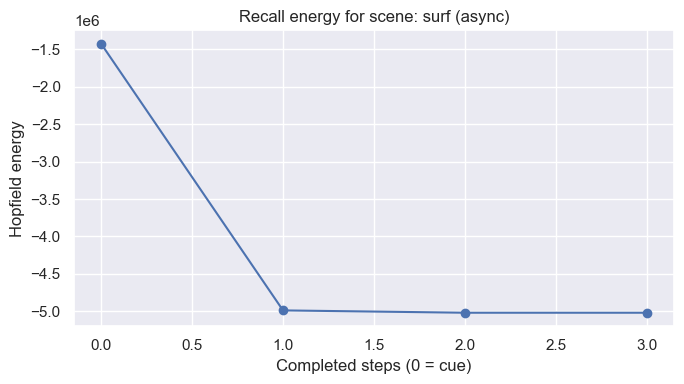

In [25]:
plt.figure(figsize=(7, 4))
plt.plot(range(len(energy_traces[-1])), energy_traces[-1], marker="o")
plt.title(f"Recall energy for scene: {last_run[0]} (async)")
plt.xlabel("Completed steps (0 = cue)")
plt.ylabel("Hopfield energy")
plt.tight_layout()
plt.show()

- Analysis of a random final scene run
- Recalled image is different from both learned patterns 
- Energy trace has a sharp drop and then levels out over the steps 
- Weights are fixed/completed (not still learning/updating) 
- Example shows an idea of energy descent/settled trajectory 

## Recall across trials

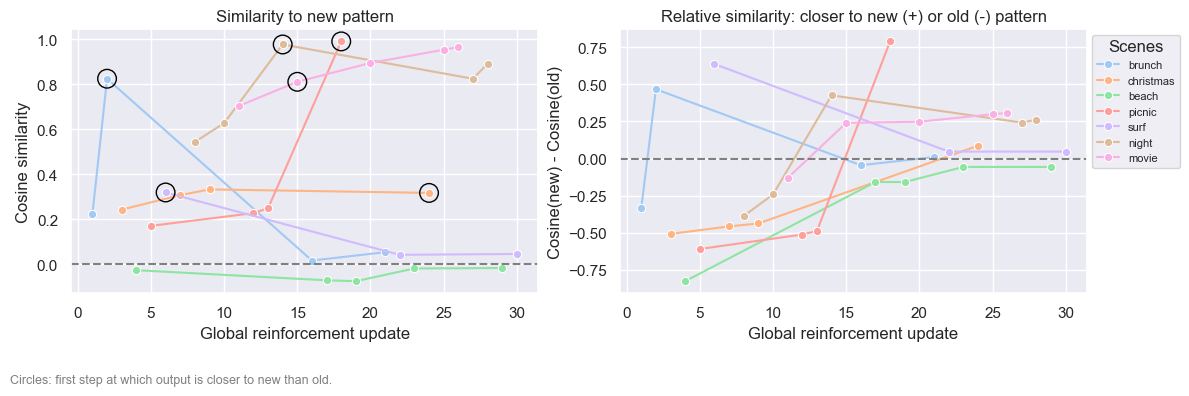

In [26]:
fig,axs = plt.subplots(1,2,figsize=(12,4))
sns.lineplot(data=new_df, x="global_step", y="cosine_new", hue="scene", marker="o", palette="pastel", ax=axs[0],legend=False)

turns = new_df[new_df["global_step"]==new_df["turnpoint"]]
axs[0].scatter(turns["global_step"],turns["cosine_new"],s=180,facecolors="none",edgecolor="black",zorder=5)

axs[0].axhline(0,linestyle="--",color="gray")    
axs[0].set(title="Similarity to new pattern", xlabel="Global reinforcement update",ylabel="Cosine similarity")
fig.text(
    0.01, 0.02,
    "Circles: first step at which output is closer to new than old.",
    fontsize=9, color="gray"
)



sns.lineplot(data=new_df, x="global_step", y="delta_cosine", hue="scene", marker="o", palette="pastel", ax=axs[1])
axs[1].axhline(0,linestyle="--",color="gray")
axs[1].set(title="Relative similarity: closer to new (+) or old (-) pattern",xlabel="Global reinforcement update",ylabel="Cosine(new) - Cosine(old)")
axs[1].legend(title="Scenes",bbox_to_anchor=(1,1),fontsize=8)
plt.tight_layout(rect=(0,0.08,1,1))
plt.show()

- Left graph = how similar output is to new pattern
- Right graph = Relative similarity from old vs new associations.
    - Positive = output more similar to new patterns
    - Negative = output more similar to old patterns 
    - 0 = equally similar to both 
- Circles in left chart indicate each scene's first step that favored the new association (does not indicate permanence)
- Each point shows recall after reinforcement and each scene is only shown when it was randomly selected 
- Outputs vary across scenes and learning stages with some showing higher new association similarity while others show weaker alignment even when the relative may suggest it's closer to new.


In [27]:
recall_count_df = pd.DataFrame({
    "match": ["Exact old","Exact new","Neither"],
    "count": [new_df["exact_old"].sum(),new_df["exact_new"].sum(), (~(new_df["exact_old"] | new_df["exact_new"])).sum()]
})
# recall_count_df

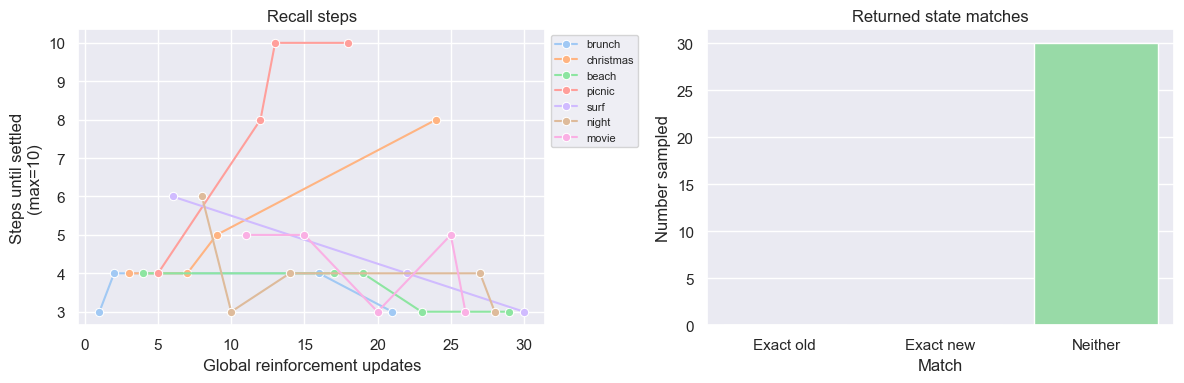

status,fixed_point,max_steps
scene,,
beach,5,0
brunch,4,0
christmas,4,0
movie,5,0
night,5,0
picnic,3,1
surf,3,0


In [28]:
fig,axs = plt.subplots(1,2,figsize=(12,4))

sns.lineplot(data=new_df, x="global_step", y="steps", hue="scene", marker="o",palette="pastel", ax=axs[0])
axs[0].set(title="Recall steps",xlabel="Global reinforcement updates",ylabel="Steps until settled\n(max=10)")
axs[0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))

sns.barplot(data=recall_count_df, x="match", y="count", hue="match",palette="pastel", ax=axs[1])
axs[1].set(title="Returned state matches",ylabel="Number sampled")
plt.xlabel("Match")
plt.tight_layout()
plt.show()

display(pd.crosstab(new_df["scene"],new_df["status"]))

- 10 steps alone does not indicate a fixed point (arbitrary stopping point)
- Settling was common but no exact reconstruction occurred in 30 trials

## Energies & fixed points 

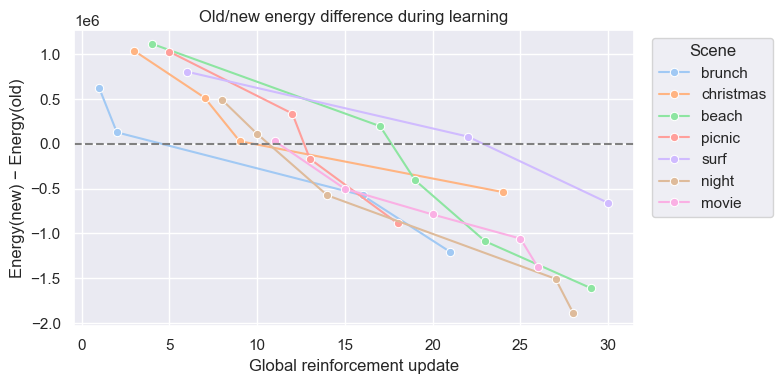

In [29]:
fig, ax = plt.subplots(figsize=(8,4))

sns.lineplot(
    data=new_df,
    x="global_step",
    y="delta_energy",
    hue="scene",
    marker="o",
    palette="pastel",
    ax=ax
)

ax.axhline(0, linestyle="--", color="gray")
ax.set(
    title="Old/new energy difference during learning",
    xlabel="Global reinforcement update",
    ylabel="Energy(new) − Energy(old)"
)
ax.legend(title="Scene", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# >0: old pattern has lower energy 
# <0: new pattern has lower energy 

- Energy of new vs old at each randomly selected scene's update
    - Positive = old patterns had lower energy 
    - Negative = new patterns had lower energy 
- We can see energy shifting towards negative values through reinforcement :) 
- Again energies evaluated via a learning weight matrix (not a fixed landscape) & each point indicates the new associated scene reinforced and measured after 

In [30]:
energy_data = []
for scene in SCENES: 
    old_pattern = memory_dict[f"{scene}_ex"]
    new_pattern = memory_dict[f"{scene}_benji"] 
    E_old = energy(W_final,old_pattern)
    E_new = energy(W_final,new_pattern)

    energy_data.append({
        "scene":scene,
        "E_old_final": E_old,
        "E_new_final": E_new,
        "delta_E": E_new - E_old,
        "old_fixed_point": is_fixed_point(W_final,old_pattern),
        "new_fixed_point": is_fixed_point(W_final,new_pattern)
    })

energy_df = pd.DataFrame(energy_data)
# energy_df

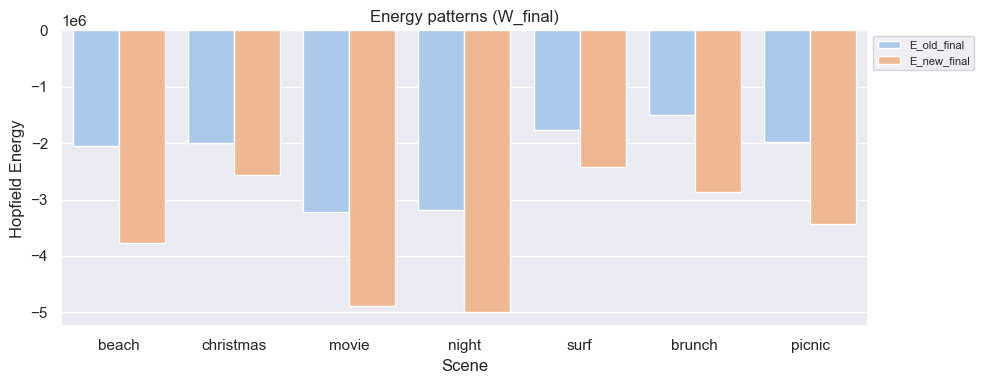

In [31]:
melt_energy_df = energy_df.melt(id_vars="scene", value_vars=["E_old_final","E_new_final"], var_name="recalled",value_name="energy")

plt.figure(figsize=(10,4))
sns.barplot(data=melt_energy_df, x="scene",y="energy",hue="recalled", palette="pastel")
plt.title("Energy patterns (W_final)")
plt.xlabel("Scene")
plt.ylabel("Hopfield Energy")
plt.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout();


In [32]:
display(energy_df[["scene","old_fixed_point","new_fixed_point"]])

,scene,old_fixed_point,new_fixed_point
0,beach,False,False
1,christmas,False,False
2,movie,False,False
3,night,False,False
4,surf,False,False
5,brunch,False,False
6,picnic,False,False


- This is based on the completed final weight matrix (W_final, post the 30 runs)
- New patterns have lower energy than older patterns but all fail the fixed point check ie there will be at least one neuron change under the update rule 
- The final matrix does not contain exact patterns as fixed points yet energy preference is towards the new associations 

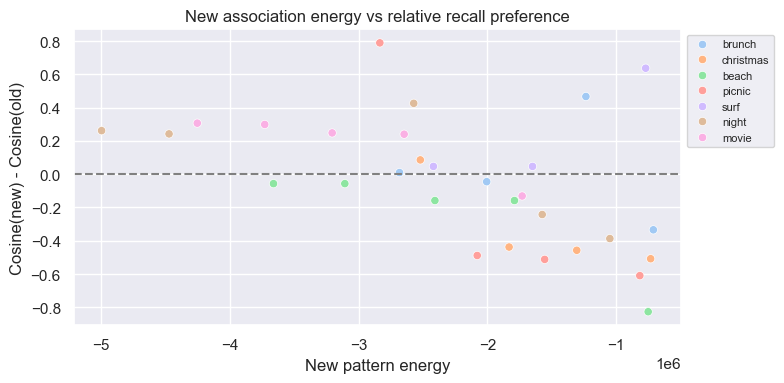

In [33]:
plt.figure(figsize=(8,4))
sns.scatterplot(data=new_df,x="energy_new",y="delta_cosine",hue="scene",marker="o",palette="pastel")
plt.axhline(0,color="gray",ls="--")
plt.title("New association energy vs relative recall preference")
plt.xlabel("New pattern energy")
plt.ylabel("Cosine(new) - Cosine(old)")
plt.legend(fontsize=8,bbox_to_anchor=(1,1))
plt.tight_layout();

- Each point = new association's energy & relative similarity preference of output at same update 
- Includes both old/new favoring outputs which suggests that energy alone cannot indicate the recall outcome
- New pattern energy: 
    - More positive = higher energy 
    - More negative = lower energy 
- Relative cosine: 
    - Positive = new association
    - Negative = old association 

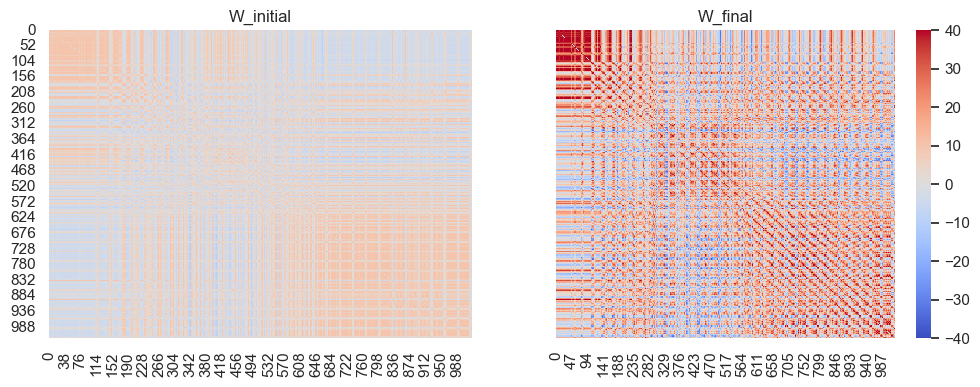

In [34]:
global_min = min(W_initial.min(), W_final.min())
global_max = max(W_initial.max(), W_final.max())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12,4),sharey=True)
sns.heatmap(W_initial, ax=ax1, vmin=global_min, vmax=global_max, cbar=False, cmap="coolwarm")
sns.heatmap(W_final, ax=ax2, vmin=global_min, vmax=global_max, cmap="coolwarm")
ax1.set_title("W_initial")
ax2.set_title("W_final")
plt.show()

- Visualization of changed weight matrices after reinforcement 

Overall: 
- Adding competing new associations changed the pattern energy and similarity preferences 
- Most retrievals indicated fixed point but none actually had an exact reconstruction of either old/new patterns 
    - New associations had lower final energy compared to old associations but neither patterns were actually fixed in the final matrix
- Observed settling, relative association preference, association energy, and reconstructions
